In [1]:
from typing import (
    TypedDict,
    Literal,
    Annotated,
)

import operator

from dotenv import load_dotenv
from pydantic import BaseModel

from langchain_openai import ChatOpenAI
from langchain_core.messages import (
    HumanMessage,
    AIMessage,
)
from langchain_core.tools import tool
from langchain.agents import create_agent

from langgraph.graph import (
    StateGraph,
    START,
    END,
    MessagesState,
)
from langgraph.types import (
    Command,
    Send,
)
from langgraph.checkpoint.memory import InMemorySaver


In [2]:
load_dotenv()

False

In [4]:
import os
import getpass

os.environ["OPENAI_API_KEY"] = getpass.getpass(
    "Enter API key: "
)

In [5]:
model = ChatOpenAI(
    model="gpt-4.1-mini",
    temperature=0,
)

OpenAIError: Missing credentials. Please pass an `api_key`, `workload_identity`, `admin_api_key`, or set the `OPENAI_API_KEY` or `OPENAI_ADMIN_KEY` environment variable.

In [6]:
def print_title(title: str):
    print("\n")
    print("=" * 80)
    print(title)
    print("=" * 80)

In [7]:
def show_graph(compiled_graph):
    """Print the generated graph as Mermaid text."""
    print(compiled_graph.get_graph().draw_mermaid())

State and routing schema

In [8]:
class RouterDecision(BaseModel):
    route: Literal[
        "technical",
        "billing",
        "general",
    ]

In [12]:
from pydantic import BaseModel, Field
from typing import Literal

class RouterDecision(BaseModel):
    route: Literal["billing", "technical"] = Field(
        description="Choose the correct support route"
    )

In [13]:
router_model = model.with_structured_output(RouterDecision)

NameError: name 'model' is not defined

In [14]:
result = router_model.invoke(
    "I have a problem with my payment"
)

print(result)

NameError: name 'router_model' is not defined

In [15]:
router_model.invoke("can you resolve the bug in my system?")

NameError: name 'router_model' is not defined

In [16]:
class RouterState(TypedDict):
    query: str
    route: str
    response: str

Router and specialist nodes

In [17]:
def router_node(state: RouterState,):

    decision = router_model.invoke(
        f"""
Route the following user query to exactly one specialist.

Available specialists:
- technical
- billing
- general

User query:
{state["query"]}
"""
    )

    return {
        "route": decision.route
    }

In [20]:
def technical_agent(state: RouterState):
    response = model.invoke(
        f"""
You are a technical support specialist.

Answer this query:
{state["query"]}
"""
    )

    return {
        "response": response.content
    }

In [21]:
def billing_agent(state: RouterState,):

    response = model.invoke(
        f"""
You are a billing support specialist.

Answer this query:
{state["query"]}
"""
    )

    return {
        "response": response.content
    }

In [22]:
def general_agent(state: RouterState,):

    response = model.invoke(
        f"""
You are a general support specialist.

Answer this query:
{state["query"]}
"""
    )

    return {
        "response": response.content
    }

In [23]:
def route_to_specialist(state: RouterState,):
    return state["route"]

Build the graph

In [29]:
def build_router_multi_agent():
    builder = StateGraph(RouterState)
    
    builder.add_node(
        "router",
        router_node,
    )

    builder.add_node(
        "technical",
        technical_agent,
    )

    builder.add_node(
        "billing",
        billing_agent,
    )

    builder.add_node(
        "general",
        general_agent,
    )

    builder.add_edge(
        START,
        "router",
    )

    builder.add_conditional_edges(
        "router",
        route_to_specialist,
        {
            "technical": "technical",
            "billing": "billing",
            "general": "general",
        },
    )

    builder.add_edge(
        "technic",
        END,
    )

    builder.add_edge(
        "billing",
        END,
    )

    builder.add_edge(
        "general",
        END,
    )

    return builder.compile()


Generated graph structure

In [26]:
router_graph = build_router_multi_agent()

In [30]:
show_graph(router_graph)

---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	router(router)
	technical(technical)
	billing(billing)
	general(general)
	__end__([<p>__end__</p>]):::last
	__start__ --> router;
	router -.-> billing;
	router -.-> general;
	router -.-> technical;
	billing --> __end__;
	general --> __end__;
	technical --> __end__;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc



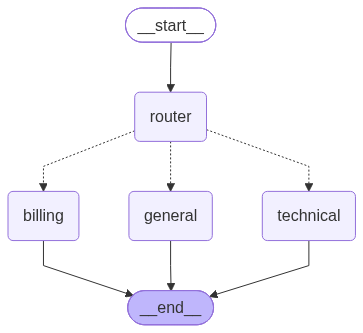

In [31]:
router_graph

In [32]:
def run_router_multi_agent():

    print_title(
        "1. ROUTER MULTI-AGENT"
    )

    graph = (build_router_multi_agent())

    result = graph.invoke(
        {
            "query":"My subscription payment was charged twice.",
            "route": "",
            "response": "",
        }
    )

    print(
        "Selected Agent:",
        result["route"],
    )

    print(
        "\nResponse:\n",
        result["response"],
    )

    return result

In [35]:
router_result = run_router_multi_agent()



1. ROUTER MULTI-AGENT


ValueError: Found edge starting at unknown node 'technic'

2. Subagents / Agent-as-Tool

In [36]:
from langchain.agents import create_agent

In [39]:
api_key = os.getenv("OPENAI_API_KEY")
if not api_key:
    api_key = getpass.getpass("Enter API key: ")
    os.environ["OPENAI_API_KEY"] = api_key

model = ChatOpenAI(
    model="gpt-4.1-mini",
    temperature=0,
    api_key=api_key,
)

research_subagent = create_agent(
    model=model,
    tools=[],
    system_prompt=(
        "You are a research specialist. "
        "Provide concise factual research."
    ),
    name="research_subagent",
)

OpenAIError: Missing credentials. Please pass an `api_key`, `workload_identity`, `admin_api_key`, or set the `OPENAI_API_KEY` or `OPENAI_ADMIN_KEY` environment variable.